In [4]:
import scipy.constants as const
import numpy as np
import matplotlib.pyplot as plt
from SpinSys import SpinSys
import SpinHamiltonian as hamil 
import calcBath as bath
import calcdIdV as dIdV
import calcESR as ESR
import SpinVisualization as vis
import calcdIdV3 as dIdV3
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


C:\Users\philou\Desktop\WillkeLab\Simulations\ternes_ldos\spinsimulation\calcBath.py:253: RuntimeWarning: overflow encountered in exp
  RateIntegrals[i, j] = abs((delta_E + V_DC) / (np.exp((delta_E + V_DC) / (spinsys.kB * spinsys.T)) - 1))
C:\Users\philou\Desktop\WillkeLab\Simulations\ternes_ldos\spinsimulation\calcBath.py:255: RuntimeWarning: invalid value encountered in scalar divide
  RateIntegrals[i, j] = abs(delta_E / (np.exp(delta_E / (spinsys.kB * spinsys.T)) - 1))


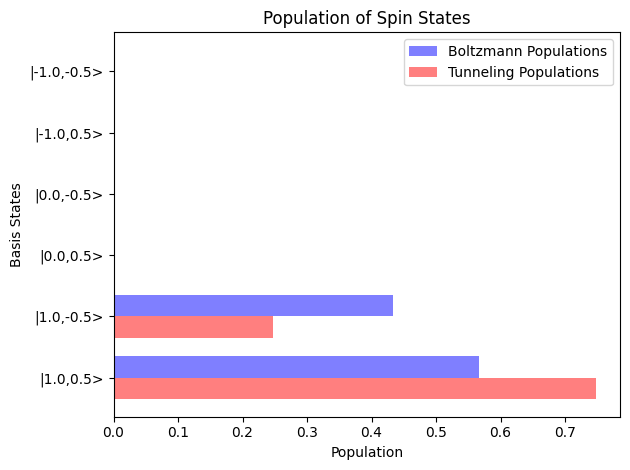

In [50]:
# Example of our Ferrimagnet
spinsys= SpinSys([1, 0.5])  # Initialize a SpinSys object
spinsys.B=[0,0,0.5] #Add a magnetic field in Tesla
spinsys.Jvector=np.array([[14,14,14]]) # Exchange coupling in meV
spinsys.Dvector=np.array([1.9,0])  # Anisotropy of the Spin 1
spinsys.AtomPositions=np.array([[0,0,0],[2,1,0]]) # Positions of the atoms in lattice units
spinsys.DipoleBool=[False] # Dipole interaction is not included


# Giving the Values for the Spn Hamiltonian
spinsys.B=[0,0,0.1]
spinsys.T=0.5  # Set temperature in Kelvin
# Tunneling Parameters
spinsys.V_DC=100
spinsys.TipPolarization=[0,0,0.7]  # Set the tip polarization
spinsys.G=1e-6  # Set the conductance in Siemens
spinsys.G_ss=[spinsys.G*1e3,spinsys.G*1e3]
spinsys.G_tt=True
#spinsys.print_parameters()

vis.plotPopulations(spinsys, AllowPumping=True, Approach="Loth")  



In [ ]:
# Plotting the Solution of the Spin Hamiltonian
#vis.plotEigenMatrix(spinsys, plot_type='p')  # Plot the eigenstate matrix as a probability heatmap
#vis.plotZeemanDiagramm(spinsys, Brange=[0,5],N=100)
#vis.plotEnergyVsSz(spinsys)  # Plot energy vs Sz matrix elements


# Calculate and plot the dI/dV spectrum
spinsys.TipPolarization=[0,0,0.4]
spinsys.T=1  # Set temperature in Kelvin
vis.plotIETS(spinsys, Vrange=[-30, 30], N=500, norm=True, order="3rd")  # Calculate and plot the IETS for the given voltage range and number of points

Found 1 potential transitions:
|0> -> |1>; f = 13.9953 GHz
Found 2 potential transitions:
|0> -> |1>; f = 13.9953 GHz
|4> -> |5>; f = 13.9953 GHz


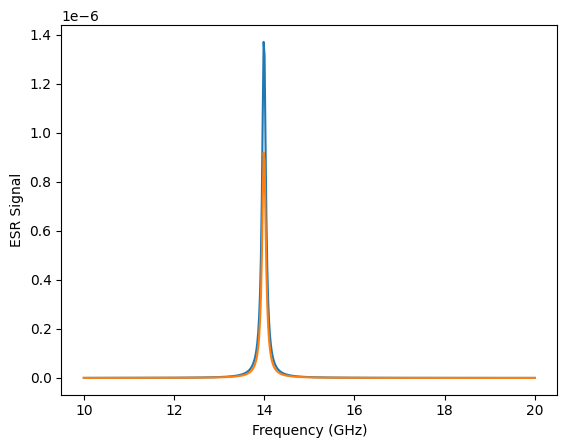

In [3]:
spinsys.B=[0, 0, 0.5]  # Set the magnetic field in Tesla
spinsys.BTip=[0.01, 0, 0]  # Set the tip magnetic field in Tesla
spinsys.T=10
spinsys.TipPolarization=[0, 0, 0.9]  # Set the tip polarization
spinsys.V_DC = -100
x0,y0 = ESR.calcESR_Benjamin(spinsys, norm=False, N=500, lw=0.1, FreqRange=[10, 20], AllowPumping=False)  # Calculate the ESR spectrum for the given parameters
xR,yR = ESR.calcESR_Benjamin(spinsys, norm=False, N=500, lw=0.1, FreqRange=[10, 20], AllowPumping=True)

# Plot the ESR spectrum
plt.figure()
plt.plot(x0, y0, label='No Pumping')
plt.plot(xR, yR, label='Pumping')
plt.xlabel('Frequency (GHz)')
plt.ylabel('ESR Signal')    
plt.show()

In [4]:
# Boltzmann constant in meV/K
kB_meV_per_K = const.Boltzmann / const.e * 1e3
kB_meV_per_K

0.08617333262145178

In [34]:
1e-12*const.e/const.h

241.7989242084918

In [29]:
spinsys.H

array([[-5.788e-02+0.j, -5.788e-08+0.j],
       [-5.788e-08+0.j,  5.788e-02+0.j]])